# 09 — Hybrid MLP-QNN
**Project:** Quantum Machine Learning for Physiological Stress Classification  
**Author:** Kenza Qribis

---

## Purpose
Implement and evaluate a Hybrid Classical-Quantum Neural Network combining a classical
fully-connected front-end with a Parameterized Quantum Circuit (PQC) backend.

## Architecture
```
26 hand-crafted physiological features
  -> Linear(64) + ReLU + Dropout(0.3)
  -> Linear(16) + ReLU
  -> Linear(n_qubits)          # bottleneck to match qubit count
  -> Tanh, then x pi           # angle encoding in (-pi, pi)
  -> Parameterized Quantum Circuit (PQC)
  -> Measurement
  -> Linear(n_classes)         # classical output head
```

## Why Hand-Crafted Features (not raw signals)?
Hand-crafted features give a compact, physiologically meaningful input for a small MLP
front-end that encodes them into qubit angles for the quantum layer. The 1D-CNN in
notebook 06 is a separate raw-signal baseline.

## Optimizer
Adam optimizer via PyTorch autograd — trains classical and quantum layers end-to-end.
Parameter-shift rule computes quantum gradients analytically via PennyLane TorchLayer.

## Data Conditions
- Full dataset (no subsampling) — deep learning needs more data than quantum kernels
- RobustScaler preprocessing (training fold); angle encoding = Tanh x pi inside the model
- LOSO cross-validation

---


In [6]:
#%pip install "numpy>=1.24,<2.0" "pandas>=2.0,<3" scipy matplotlib seaborn scikit-learn torch "pennylane>=0.35" tqdm joblib ipywidgets

In [7]:
import torch, pennylane, pandas, numpy
print(torch.__version__, pennylane.__version__, pandas.__version__, numpy.__version__)

2.11.0+cpu 0.44.1 3.0.2 2.4.4


## 0. Configuration & Imports

In [8]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler

import pennylane as qml
from pennylane import numpy as pnp

from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

warnings.filterwarnings('ignore')

RESULTS_ROOT    = os.path.join('..', 'results')
PLOTS_DIR       = os.path.join(RESULTS_ROOT, 'plots', '09_hybrid_mlp_qnn')
LOGS_DIR        = os.path.join(RESULTS_ROOT, 'logs')
OUTPUT_DATA_DIR = os.path.join(RESULTS_ROOT, 'output_data')
for d in [PLOTS_DIR, LOGS_DIR, OUTPUT_DATA_DIR]:
    os.makedirs(d, exist_ok=True)

ECG_FEATURE_PREFIXES = ['ecg_']
RANDOM_STATE         = 42
DEVICE               = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Hybrid model config ───────────────────────────────────────────────────────
N_QUBITS    = 4      # quantum layer width
N_LAYERS    = 2      # PQC depth (number of variational layers)
EPOCHS      = 40
BATCH_SIZE  = 32
LR          = 1e-3

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size']  = 11
sns.set_style('whitegrid')

print('Configuration ready.')
print(f'  Device    : {DEVICE}')
print(f'  N qubits  : {N_QUBITS}')
print(f'  PQC layers: {N_LAYERS}')
print(f'  Epochs    : {EPOCHS}')
print(f'  LR        : {LR}')


Configuration ready.
  Device    : cpu
  N qubits  : 4
  PQC layers: 2
  Epochs    : 40
  LR        : 0.001


## 1. Load Datasets

In [9]:
df_wesad_bin = pd.read_csv(
    os.path.join(OUTPUT_DATA_DIR, 'wesad_features_binary.csv'))
df_wesad_3cl = pd.read_csv(
    os.path.join(OUTPUT_DATA_DIR, 'wesad_features_3class.csv'))
wesad_feat_cols = json.load(
    open(os.path.join(OUTPUT_DATA_DIR, 'feature_columns.json')))

df_dreamer = pd.read_csv(
    os.path.join(OUTPUT_DATA_DIR, 'dreamer_features_binary.csv'))
dreamer_all_feats = json.load(
    open(os.path.join(OUTPUT_DATA_DIR, 'dreamer_feature_columns.json')))
dreamer_eeg_feats = [c for c in dreamer_all_feats
                     if not any(c.startswith(p) for p in ECG_FEATURE_PREFIXES)]

# Remove all-NaN columns from feature lists
all_nan_wesad = ['resp_mean_rate', 'resp_std_rate', 
                 'resp_mean_amp', 'resp_std_amp']
wesad_feat_cols = [c for c in wesad_feat_cols 
                   if c not in all_nan_wesad]

all_nan_dreamer = [c for c in dreamer_eeg_feats 
                   if df_dreamer[c].isna().all()]
dreamer_eeg_feats = [c for c in dreamer_eeg_feats 
                     if c not in all_nan_dreamer]

print(f'WESAD features after cleanup  : {len(wesad_feat_cols)}')
print(f'DREAMER features after cleanup: {len(dreamer_eeg_feats)}')

print('=== Datasets Loaded ===')
print(f'WESAD binary   : {df_wesad_bin.shape}  features={len(wesad_feat_cols)}')
print(f'WESAD 3-class  : {df_wesad_3cl.shape}')
print(f'DREAMER binary : {df_dreamer.shape}  EEG features={len(dreamer_eeg_feats)}')


WESAD features after cleanup  : 22
DREAMER features after cleanup: 134
=== Datasets Loaded ===
WESAD binary   : (883, 30)  features=22
WESAD 3-class  : (1049, 30)
DREAMER binary : (414, 146)  EEG features=134


In [10]:
# ---- A4: per-subject z-score of the feature windows (same idea as the 1D-CNN in notebook 06) ----
PER_SUBJECT_ZSCORE = True   # False = old tables (only A5 changed). True = per-subject z-scored features.

def zscore_per_subject(df, feature_cols, subject_col='subject_id'):
    """Z-score each feature within each subject (all of that subject's windows). Label-free."""
    out = df.copy()
    out[feature_cols] = (out.groupby(subject_col)[feature_cols]
                         .transform(lambda s: (s - s.mean()) / (s.std(ddof=0) + 1e-8)))
    return out

if PER_SUBJECT_ZSCORE:
    df_wesad_bin = zscore_per_subject(df_wesad_bin, wesad_feat_cols)
    df_wesad_3cl = zscore_per_subject(df_wesad_3cl, wesad_feat_cols)
print('Per-subject z-score:', PER_SUBJECT_ZSCORE)

Per-subject z-score: True


## 2. PennyLane Quantum Circuit

Quantum circuit defined.
  Qubits            : 4
  Variational layers: 2
  Trainable params  : 8
  Embedding         : AngleEmbedding (Y rotation)
  Ansatz            : BasicEntanglerLayers
  Diff method       : parameter-shift (batched)

Circuit diagram:
0: ─╭AngleEmbedding(M0)─╭BasicEntanglerLayers(M1)─┤  <Z>
1: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
2: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
3: ─╰AngleEmbedding(M0)─╰BasicEntanglerLayers(M1)─┤  <Z>

M0 = 
[0. 0. 0. 0.]
M1 = 
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]]


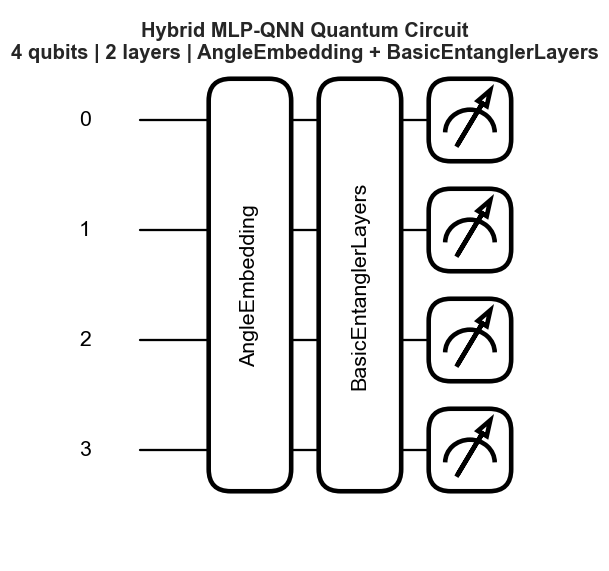

Saved: ..\results\plots\09_hybrid_mlp_qnn\hybrid_quantum_circuit.png


In [11]:
# PennyLane device — default.qubit statevector simulator
dev = qml.device('default.qubit', wires=N_QUBITS)


@qml.qnode(dev, interface='torch', diff_method='backprop')
def quantum_circuit(inputs, weights):
    """
    Parameterized quantum circuit with batched processing.
    inputs  : (N_QUBITS,) or (batch, N_QUBITS) — angle-encoded data
    weights : (N_LAYERS, N_QUBITS) — trainable rotation angles
    Returns : expectation values of PauliZ on each qubit
    """
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation='Y')
    qml.BasicEntanglerLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]


# Wrap as TorchLayer — supports batched forward pass
weight_shapes = {'weights': (N_LAYERS, N_QUBITS)}
quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)

print('Quantum circuit defined.')
print(f'  Qubits            : {N_QUBITS}')
print(f'  Variational layers: {N_LAYERS}')
print(f'  Trainable params  : {N_LAYERS * N_QUBITS}')
print(f'  Embedding         : AngleEmbedding (Y rotation)')
print(f'  Ansatz            : BasicEntanglerLayers')
print(f'  Diff method       : parameter-shift (batched)')

# Draw circuit
print('\nCircuit diagram:')
inputs_ex  = pnp.zeros(N_QUBITS)
weights_ex = pnp.zeros((N_LAYERS, N_QUBITS))
print(qml.draw(quantum_circuit)(inputs_ex, weights_ex))

# Save circuit diagram
fig, ax = qml.draw_mpl(quantum_circuit, expansion_strategy='device')(inputs_ex, weights_ex)
fig.suptitle(f'Hybrid MLP-QNN Quantum Circuit\n'
             f'{N_QUBITS} qubits | {N_LAYERS} layers | '
             f'AngleEmbedding + BasicEntanglerLayers',
             fontweight='bold')
p = os.path.join(PLOTS_DIR, 'hybrid_quantum_circuit.png')
fig.savefig(p, bbox_inches='tight', dpi=150)
plt.show()
print(f'Saved: {p}')

## 3. Hybrid MLP-QNN Architecture

In [12]:
class HybridMLPQNN(nn.Module):
    """
    Hybrid Classical-Quantum Neural Network.
    use_quantum=False replaces the PQC with a classical layer of the same width
    (Linear + Tanh, output in [-1, 1] like the PauliZ expectations) — ablation.
    """
    def __init__(self, n_features, n_qubits, n_classes, dropout=0.3, use_quantum=True):
        super().__init__()
        self.n_qubits  = n_qubits
        self.n_classes = n_classes

        # Classical front-end
        self.classical_front = nn.Sequential(
            nn.Linear(n_features, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 16),
            nn.ReLU(),
            nn.Linear(16, n_qubits),
            nn.Tanh()   # bound output to (-1, 1) before angle scaling
        )

        # Angle scaling: map (-1,1) to (-pi, pi)
        self.angle_scale = np.pi

        # Middle layer: quantum circuit, or classical stand-in for the ablation
        if use_quantum:
            self.quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        else:
            self.quantum_layer = nn.Sequential(nn.Linear(n_qubits, n_qubits), nn.Tanh())

        # Classical output head
        self.classical_out = nn.Linear(n_qubits, n_classes)

    def forward(self, x):
        x = self.classical_front(x)          # (batch, n_qubits)
        x = x * self.angle_scale             # scale to (-pi, pi)
        middle_out = self.quantum_layer(x)   # (batch, n_qubits)
        return self.classical_out(middle_out)


# Architecture test
_model = HybridMLPQNN(n_features=26, n_qubits=N_QUBITS, n_classes=2)
_x     = torch.randn(4, 26)
_out   = _model(_x)
print(f'Architecture test: input={list(_x.shape)} -> output={list(_out.shape)}')
total_params = sum(p.numel() for p in _model.parameters() if p.requires_grad)
print(f'Total trainable parameters: {total_params}')
classical_params = sum(p.numel() for p in _model.classical_front.parameters()) + \
                   sum(p.numel() for p in _model.classical_out.parameters())
print(f'  Classical params : {classical_params}')
print(f'  Quantum params   : {total_params - classical_params}')
del _model, _x, _out

_m1 = HybridMLPQNN(n_features=26, n_qubits=N_QUBITS, n_classes=2)
_m2 = HybridMLPQNN(n_features=26, n_qubits=N_QUBITS, n_classes=2)
print(_m1.quantum_layer is _m2.quantum_layer)   # must print False
_abl = HybridMLPQNN(n_features=26, n_qubits=N_QUBITS, n_classes=2, use_quantum=False)
print('Ablation middle-layer params:', sum(p.numel() for p in _abl.quantum_layer.parameters()))  # 20
del _m1, _m2, _abl

Architecture test: input=[4, 26] -> output=[4, 2]
Total trainable parameters: 2854
  Classical params : 2846
  Quantum params   : 8
False
Ablation middle-layer params: 20


## 4. Training Utilities

In [13]:
def get_weighted_sampler(y):
    counts  = np.bincount(y)
    weights = 1.0 / counts[y]
    return WeightedRandomSampler(
        torch.tensor(weights, dtype=torch.float32),
        num_samples=len(weights), replacement=True)


def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for X_batch, y_batch in loader:
        optimizer.zero_grad()
        out  = model(X_batch)
        loss = criterion(out, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y_batch)
        correct    += (out.argmax(1) == y_batch).sum().item()
        total      += len(y_batch)
    return total_loss / total, correct / total


def eval_model(model, loader, criterion):
    model.eval()
    all_preds, all_true = [], []
    total_loss, total = 0, 0
    with torch.no_grad():
        for X_batch, y_batch in loader:
            out   = model(X_batch)
            loss  = criterion(out, y_batch)
            total_loss += loss.item() * len(y_batch)
            total      += len(y_batch)
            all_preds.extend(out.argmax(1).numpy().tolist())
            all_true.extend(y_batch.numpy().tolist())
    return total_loss/total, all_preds, all_true


def compute_metrics(y_true, y_pred, average='macro'):
    return {
        'accuracy' : float(accuracy_score(y_true, y_pred)),
        'precision': float(precision_score(y_true, y_pred,
                           average=average, zero_division=0)),
        'recall'   : float(recall_score(y_true, y_pred,
                           average=average, zero_division=0)),
        'f1'       : float(f1_score(y_true, y_pred,
                           average=average, zero_division=0)),
    }


print('Training utilities defined.')


Training utilities defined.


## 5. LOSO Pipeline

In [14]:
def run_hybrid_loso(df, feature_cols, label_col, subject_col,
                    task_name, average='macro', use_quantum=True, seed=0):
    """
    LOSO cross-validation for the Hybrid MLP-QNN.
    Uses full dataset (no subsampling) — deep learning needs more data.
    """
    subjects  = sorted(df[subject_col].unique())
    classes   = sorted(df[label_col].unique())
    n_cls     = len(classes)
    n_feats   = len(feature_cols)

    fold_rows  = []
    cm_accum   = np.zeros((n_cls, n_cls), dtype=int)
    train_curves = []

    print(f'\n=== {task_name} — Hybrid LOSO ({len(subjects)} folds) ===')
    print(f'    Epochs={EPOCHS}  BS={BATCH_SIZE}  LR={LR}  Qubits={N_QUBITS}')

    for fold_i, test_sid in enumerate(subjects):
        torch.manual_seed(RANDOM_STATE + 1000 * seed + fold_i)   # reproducible per fold

        train_mask = df[subject_col] != test_sid
        test_mask  = df[subject_col] == test_sid

        X_train = df.loc[train_mask, feature_cols].values.astype(float)
        y_train = df.loc[train_mask, label_col].values.astype(int)
        X_test  = df.loc[test_mask,  feature_cols].values.astype(float)
        y_test  = df.loc[test_mask,  label_col].values.astype(int)

        # Impute
        imputer = SimpleImputer(strategy='median')
        X_train = imputer.fit_transform(X_train)
        X_test  = imputer.transform(X_test)

        # RobustScaler
        scaler  = RobustScaler()
        X_train = scaler.fit_transform(X_train)
        X_test  = scaler.transform(X_test)

        # Convert to tensors
        X_tr_t = torch.tensor(X_train, dtype=torch.float32)
        y_tr_t = torch.tensor(y_train, dtype=torch.long)
        X_te_t = torch.tensor(X_test,  dtype=torch.float32)
        y_te_t = torch.tensor(y_test,  dtype=torch.long)

        # Weighted sampler for class imbalance
        sampler      = get_weighted_sampler(y_train)
        train_ds     = TensorDataset(X_tr_t, y_tr_t)
        test_ds      = TensorDataset(X_te_t, y_te_t)
        train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                                  sampler=sampler)
        test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                                  shuffle=False)

        # Fresh model each fold (new quantum weights every fold)
        model     = HybridMLPQNN(n_features=n_feats,
                                  n_qubits=N_QUBITS,
                                  n_classes=n_cls,
                                  use_quantum=use_quantum)
        optimizer = optim.Adam(model.parameters(), lr=LR,
                               weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(
                               optimizer, step_size=15, gamma=0.5)
        criterion = nn.CrossEntropyLoss()

        # Train
        t0 = time.time()
        for epoch in range(EPOCHS):
            tr_loss, tr_acc = train_epoch(
                model, train_loader, optimizer, criterion)
            scheduler.step()
            train_curves.append({
                'fold': fold_i+1, 'epoch': epoch+1,
                'train_loss': tr_loss, 'train_acc': tr_acc
            })
        train_time = time.time() - t0

        # Evaluate
        t1 = time.time()
        _, y_pred, y_true = eval_model(model, test_loader, criterion)
        test_time = time.time() - t1

        metrics = compute_metrics(y_true, y_pred, average=average)
        cm      = confusion_matrix(y_true, y_pred, labels=classes)
        cm_accum += cm

        fold_rows.append({
            'task'        : task_name,
            'model'       : 'Hybrid MLP-QNN' if use_quantum else 'Hybrid (classical ablation)',
            'seed'        : seed,
            'fold'        : fold_i + 1,
            'test_subject': int(test_sid),
            'train_size'  : len(y_train),
            'test_size'   : len(y_test),
            'train_time'  : round(train_time, 2),
            'test_time'   : round(test_time, 4),
            **metrics
        })

        print(f'  Fold {fold_i+1:2d}/{len(subjects)} '
              f'test=S{test_sid:2d}  '
              f'acc={metrics["accuracy"]:.3f}  '
              f'f1={metrics["f1"]:.3f}  '
              f'train={train_time:.0f}s')

        del model

    return (pd.DataFrame(fold_rows),
            cm_accum,
            pd.DataFrame(train_curves))


print('Hybrid LOSO pipeline defined.')

Hybrid LOSO pipeline defined.


In [15]:
# Multi-seed hybrid + classical ablation (saves after every run, so nothing is lost if it stops)
TASKS = [
    dict(df=df_wesad_bin, feature_cols=wesad_feat_cols, label_col='label_encoded',
         subject_col='subject_id', task_name='WESAD_binary_Hybrid'),
    dict(df=df_wesad_3cl, feature_cols=wesad_feat_cols, label_col='label_encoded',
         subject_col='subject_id', task_name='WESAD_3class_Hybrid'),
    dict(df=df_dreamer, feature_cols=dreamer_eeg_feats, label_col='arousal_binary',
         subject_col='subject_id', task_name='DREAMER_binary_EEG_Hybrid'),
]
SEEDS = [0, 1, 2, 3, 4]
out_path = os.path.join(OUTPUT_DATA_DIR, 'hybrid_multiseed_per_fold.csv')

runs = []
for use_q in [True, False]:
    for s in SEEDS:
        for t in TASKS:
            res, _, _ = run_hybrid_loso(**t, use_quantum=use_q, seed=s)
            runs.append(res)
            pd.concat(runs, ignore_index=True).to_csv(out_path, index=False)

multi = pd.concat(runs, ignore_index=True)
per_seed = multi.groupby(['task', 'model', 'seed'])['f1'].mean()
summary = per_seed.groupby(['task', 'model']).agg(['mean', 'std']).round(4)
summary.to_csv(os.path.join(OUTPUT_DATA_DIR, 'hybrid_multiseed_summary.csv'))
print(summary)


=== WESAD_binary_Hybrid — Hybrid LOSO (15 folds) ===
    Epochs=40  BS=32  LR=0.001  Qubits=4
  Fold  1/15 test=S 2  acc=0.911  f1=0.906  train=16s
  Fold  2/15 test=S 3  acc=0.895  f1=0.891  train=35s
  Fold  3/15 test=S 4  acc=1.000  f1=1.000  train=33s
  Fold  4/15 test=S 5  acc=1.000  f1=1.000  train=13s
  Fold  5/15 test=S 6  acc=0.983  f1=0.981  train=12s
  Fold  6/15 test=S 7  acc=0.983  f1=0.981  train=12s
  Fold  7/15 test=S 8  acc=0.983  f1=0.981  train=12s
  Fold  8/15 test=S 9  acc=0.914  f1=0.909  train=12s
  Fold  9/15 test=S10  acc=1.000  f1=1.000  train=12s
  Fold 10/15 test=S11  acc=1.000  f1=1.000  train=12s
  Fold 11/15 test=S13  acc=1.000  f1=1.000  train=12s
  Fold 12/15 test=S14  acc=1.000  f1=1.000  train=21s
  Fold 13/15 test=S15  acc=0.983  f1=0.982  train=35s
  Fold 14/15 test=S16  acc=1.000  f1=1.000  train=30s
  Fold 15/15 test=S17  acc=1.000  f1=1.000  train=13s

=== WESAD_3class_Hybrid — Hybrid LOSO (15 folds) ===
    Epochs=40  BS=32  LR=0.001  Qubits=4


## 6. WESAD Binary Task
> Expect 20-40 minutes.

In [16]:
results_wb, cm_wb, curves_wb = run_hybrid_loso(
    df           = df_wesad_bin,
    feature_cols = wesad_feat_cols,
    label_col    = 'label_encoded',
    subject_col  = 'subject_id',
    task_name    = 'WESAD_binary_Hybrid',
)
print('\n=== WESAD Binary Hybrid — Mean Metrics ===')
print(results_wb[['accuracy','precision','recall','f1',
                   'train_time']].mean().round(4).to_string())
print(f'Std F1: {results_wb["f1"].std():.4f}')



=== WESAD_binary_Hybrid — Hybrid LOSO (15 folds) ===
    Epochs=40  BS=32  LR=0.001  Qubits=4
  Fold  1/15 test=S 2  acc=0.911  f1=0.906  train=37s
  Fold  2/15 test=S 3  acc=0.895  f1=0.891  train=19s
  Fold  3/15 test=S 4  acc=1.000  f1=1.000  train=16s
  Fold  4/15 test=S 5  acc=1.000  f1=1.000  train=15s
  Fold  5/15 test=S 6  acc=0.983  f1=0.981  train=14s
  Fold  6/15 test=S 7  acc=0.983  f1=0.981  train=14s
  Fold  7/15 test=S 8  acc=0.983  f1=0.981  train=14s
  Fold  8/15 test=S 9  acc=0.914  f1=0.909  train=15s
  Fold  9/15 test=S10  acc=1.000  f1=1.000  train=15s
  Fold 10/15 test=S11  acc=1.000  f1=1.000  train=14s
  Fold 11/15 test=S13  acc=1.000  f1=1.000  train=15s
  Fold 12/15 test=S14  acc=1.000  f1=1.000  train=15s
  Fold 13/15 test=S15  acc=0.983  f1=0.982  train=15s
  Fold 14/15 test=S16  acc=1.000  f1=1.000  train=15s
  Fold 15/15 test=S17  acc=1.000  f1=1.000  train=15s

=== WESAD Binary Hybrid — Mean Metrics ===
accuracy       0.9768
precision      0.9753
recall 

## 7. WESAD 3-Class Task

In [17]:
results_w3, cm_w3, curves_w3 = run_hybrid_loso(
    df           = df_wesad_3cl,
    feature_cols = wesad_feat_cols,
    label_col    = 'label_encoded',
    subject_col  = 'subject_id',
    task_name    = 'WESAD_3class_Hybrid',
    average      = 'macro',
)
print('\n=== WESAD 3-Class Hybrid — Mean Metrics ===')
print(results_w3[['accuracy','precision','recall','f1',
                   'train_time']].mean().round(4).to_string())
print(f'Std F1: {results_w3["f1"].std():.4f}')



=== WESAD_3class_Hybrid — Hybrid LOSO (15 folds) ===
    Epochs=40  BS=32  LR=0.001  Qubits=4
  Fold  1/15 test=S 2  acc=0.866  f1=0.870  train=18s
  Fold  2/15 test=S 3  acc=0.750  f1=0.672  train=17s
  Fold  3/15 test=S 4  acc=0.838  f1=0.670  train=17s
  Fold  4/15 test=S 5  acc=0.986  f1=0.981  train=17s
  Fold  5/15 test=S 6  acc=0.929  f1=0.895  train=17s
  Fold  6/15 test=S 7  acc=0.886  f1=0.802  train=17s
  Fold  7/15 test=S 8  acc=0.671  f1=0.622  train=20s
  Fold  8/15 test=S 9  acc=0.643  f1=0.529  train=17s
  Fold  9/15 test=S10  acc=0.901  f1=0.846  train=18s
  Fold 10/15 test=S11  acc=0.971  f1=0.963  train=17s
  Fold 11/15 test=S13  acc=0.829  f1=0.769  train=16s
  Fold 12/15 test=S14  acc=0.914  f1=0.900  train=17s
  Fold 13/15 test=S15  acc=0.930  f1=0.896  train=17s
  Fold 14/15 test=S16  acc=0.958  f1=0.947  train=17s
  Fold 15/15 test=S17  acc=0.847  f1=0.705  train=17s

=== WESAD 3-Class Hybrid — Mean Metrics ===
accuracy       0.8613
precision      0.8431
recall

## 8. DREAMER Binary EEG Task

In [18]:
results_db, cm_db, curves_db = run_hybrid_loso(
    df           = df_dreamer,
    feature_cols = dreamer_eeg_feats,
    label_col    = 'arousal_binary',
    subject_col  = 'subject_id',
    task_name    = 'DREAMER_binary_EEG_Hybrid',
    average      = 'macro',
)
print('\n=== DREAMER Binary EEG Hybrid — Mean Metrics ===')
print(results_db[['accuracy','precision','recall','f1',
                   'train_time']].mean().round(4).to_string())
print(f'Std F1: {results_db["f1"].std():.4f}')



=== DREAMER_binary_EEG_Hybrid — Hybrid LOSO (23 folds) ===
    Epochs=40  BS=32  LR=0.001  Qubits=4
  Fold  1/23 test=S 1  acc=0.500  f1=0.458  train=8s
  Fold  2/23 test=S 2  acc=0.444  f1=0.438  train=8s
  Fold  3/23 test=S 3  acc=0.500  f1=0.498  train=7s
  Fold  4/23 test=S 4  acc=0.500  f1=0.333  train=7s
  Fold  5/23 test=S 5  acc=0.389  f1=0.387  train=7s
  Fold  6/23 test=S 6  acc=0.556  f1=0.532  train=7s
  Fold  7/23 test=S 7  acc=0.611  f1=0.600  train=8s
  Fold  8/23 test=S 8  acc=0.333  f1=0.299  train=7s
  Fold  9/23 test=S 9  acc=0.333  f1=0.325  train=7s
  Fold 10/23 test=S10  acc=0.500  f1=0.458  train=8s
  Fold 11/23 test=S11  acc=0.444  f1=0.308  train=8s
  Fold 12/23 test=S12  acc=0.444  f1=0.438  train=8s
  Fold 13/23 test=S13  acc=0.556  f1=0.532  train=8s
  Fold 14/23 test=S14  acc=0.444  f1=0.444  train=7s
  Fold 15/23 test=S15  acc=0.500  f1=0.498  train=8s
  Fold 16/23 test=S16  acc=0.278  f1=0.217  train=8s
  Fold 17/23 test=S17  acc=0.500  f1=0.458  train=8

## 9. Results & Plots

In [19]:
all_hybrid = pd.concat([results_wb, results_w3, results_db],
                        ignore_index=True)

summary_hybrid = (
    all_hybrid.groupby('task')
    .agg(
        accuracy_mean  = ('accuracy',  'mean'),
        accuracy_std   = ('accuracy',  'std'),
        precision_mean = ('precision', 'mean'),
        recall_mean    = ('recall',    'mean'),
        f1_mean        = ('f1',        'mean'),
        f1_std         = ('f1',        'std'),
        train_time_mean= ('train_time','mean'),
    )
    .round(4).reset_index()
)
summary_hybrid['model'] = 'Hybrid MLP-QNN'

print('=== HYBRID MLP-QNN SUMMARY ===')
print(summary_hybrid.to_string(index=False))

p = os.path.join(OUTPUT_DATA_DIR, 'hybrid_mlp_qnn_summary.csv')
summary_hybrid.to_csv(p, index=False)
print(f'\nSaved: {p}')

p2 = os.path.join(OUTPUT_DATA_DIR, 'hybrid_mlp_qnn_per_fold.csv')
all_hybrid.to_csv(p2, index=False)
print(f'Saved: {p2}')


=== HYBRID MLP-QNN SUMMARY ===
                     task  accuracy_mean  accuracy_std  precision_mean  recall_mean  f1_mean  f1_std  train_time_mean          model
DREAMER_binary_EEG_Hybrid         0.4517        0.0907          0.4706       0.4622   0.4173  0.1016           7.5204 Hybrid MLP-QNN
      WESAD_3class_Hybrid         0.8613        0.1032          0.8431       0.8145   0.8044  0.1374          17.4233 Hybrid MLP-QNN
      WESAD_binary_Hybrid         0.9768        0.0374          0.9753       0.9793   0.9754  0.0391          16.5400 Hybrid MLP-QNN

Saved: ..\results\output_data\hybrid_mlp_qnn_summary.csv
Saved: ..\results\output_data\hybrid_mlp_qnn_per_fold.csv


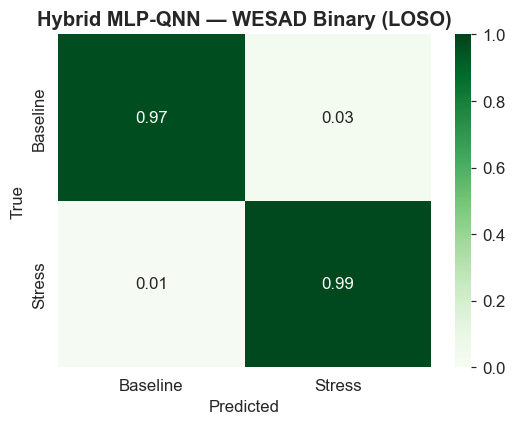

Saved: ..\results\plots\09_hybrid_mlp_qnn\cm_hybrid_wesad_binary.png


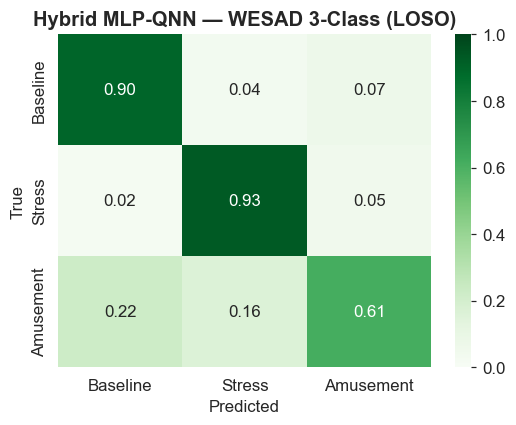

Saved: ..\results\plots\09_hybrid_mlp_qnn\cm_hybrid_wesad_3class.png


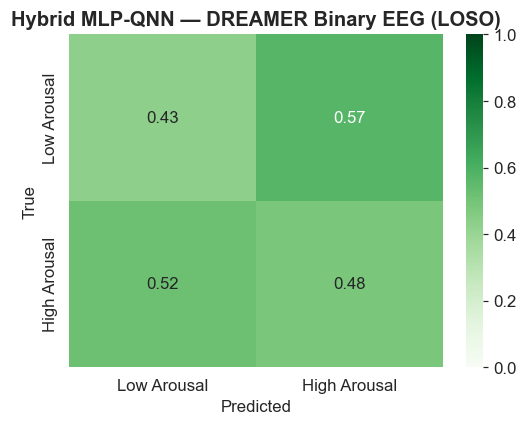

Saved: ..\results\plots\09_hybrid_mlp_qnn\cm_hybrid_dreamer_binary.png


In [20]:
# Confusion matrices
def plot_cm(cm, class_names, title, save_path):
    fig, ax = plt.subplots(figsize=(5, 4))
    cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-10)
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
                xticklabels=class_names, yticklabels=class_names,
                ax=ax, vmin=0, vmax=1, annot_kws={'size':11})
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    plt.tight_layout()
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()
    print(f'Saved: {save_path}')

plot_cm(cm_wb, ['Baseline','Stress'],
        'Hybrid MLP-QNN — WESAD Binary (LOSO)',
        os.path.join(PLOTS_DIR, 'cm_hybrid_wesad_binary.png'))
plot_cm(cm_w3, ['Baseline','Stress','Amusement'],
        'Hybrid MLP-QNN — WESAD 3-Class (LOSO)',
        os.path.join(PLOTS_DIR, 'cm_hybrid_wesad_3class.png'))
plot_cm(cm_db, ['Low Arousal','High Arousal'],
        'Hybrid MLP-QNN — DREAMER Binary EEG (LOSO)',
        os.path.join(PLOTS_DIR, 'cm_hybrid_dreamer_binary.png'))


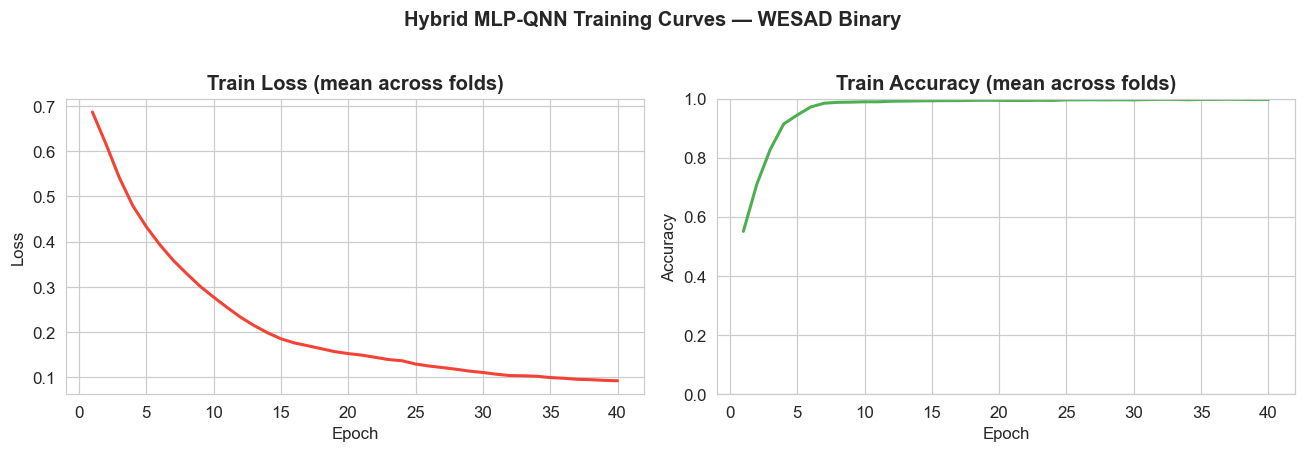

Saved: ..\results\plots\09_hybrid_mlp_qnn\curves_hybrid_wesad_binary.png


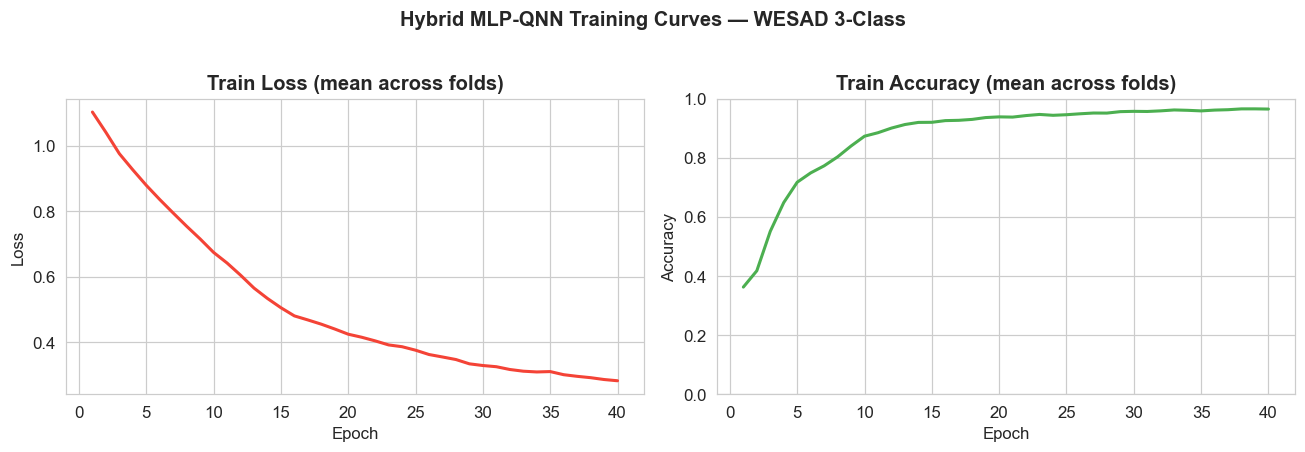

Saved: ..\results\plots\09_hybrid_mlp_qnn\curves_hybrid_wesad_3class.png


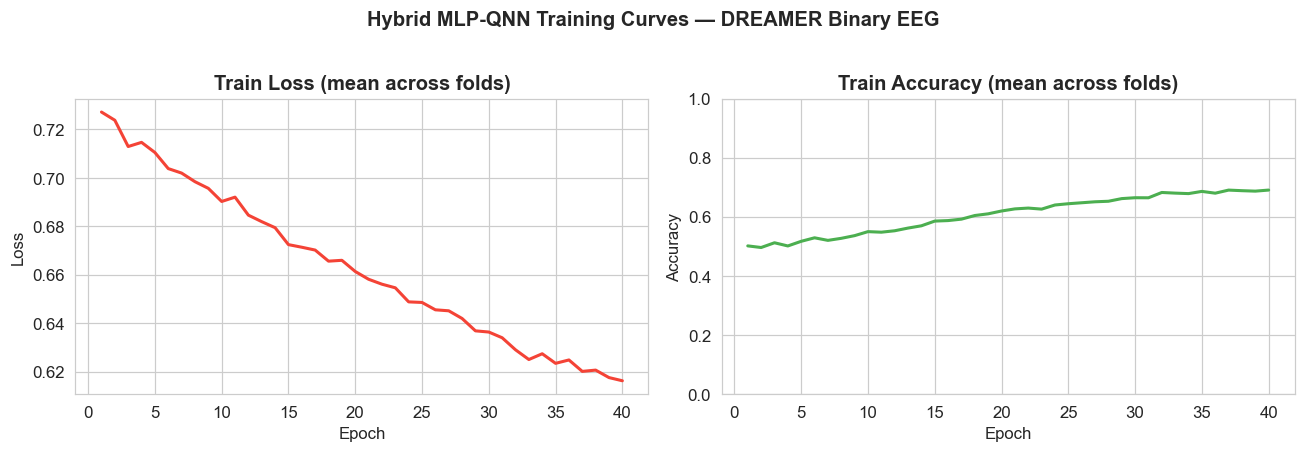

Saved: ..\results\plots\09_hybrid_mlp_qnn\curves_hybrid_dreamer.png


In [21]:
# Training curves — mean across folds
for curves, task_label, fname in [
        (curves_wb, 'WESAD Binary',       'curves_hybrid_wesad_binary.png'),
        (curves_w3, 'WESAD 3-Class',      'curves_hybrid_wesad_3class.png'),
        (curves_db, 'DREAMER Binary EEG', 'curves_hybrid_dreamer.png')]:

    mean_c = curves.groupby('epoch')[['train_loss','train_acc']].mean()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(mean_c.index, mean_c['train_loss'], color='#F44336', lw=2)
    axes[0].set_title('Train Loss (mean across folds)', fontweight='bold')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
    axes[1].plot(mean_c.index, mean_c['train_acc'], color='#4CAF50', lw=2)
    axes[1].set_title('Train Accuracy (mean across folds)', fontweight='bold')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
    axes[1].set_ylim(0, 1)
    plt.suptitle(f'Hybrid MLP-QNN Training Curves — {task_label}',
                 fontweight='bold', y=1.02)
    plt.tight_layout()
    p = os.path.join(PLOTS_DIR, fname)
    plt.savefig(p, bbox_inches='tight'); plt.show()
    print(f'Saved: {p}')


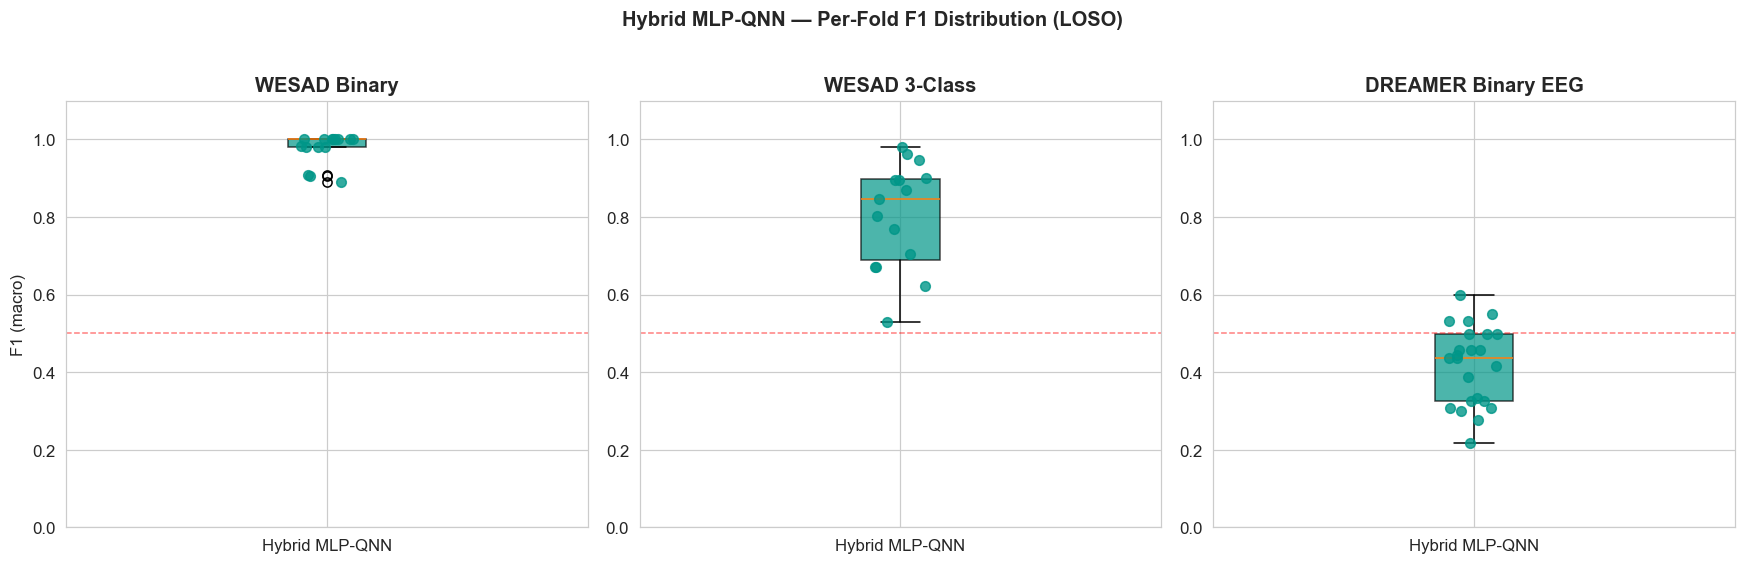

Saved: ..\results\plots\09_hybrid_mlp_qnn\hybrid_f1_per_fold_boxplot.png


In [22]:
# Per-fold F1 boxplot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
task_pairs = [
    ('WESAD_binary_Hybrid',      'WESAD Binary'),
    ('WESAD_3class_Hybrid',      'WESAD 3-Class'),
    ('DREAMER_binary_EEG_Hybrid','DREAMER Binary EEG'),
]
for ax, (task_key, task_label) in zip(axes, task_pairs):
    td = all_hybrid[all_hybrid['task']==task_key]['f1'].values
    ax.boxplot([td], patch_artist=True, tick_labels=['Hybrid MLP-QNN'],
               boxprops=dict(facecolor='#009688', alpha=0.7))
    ax.scatter(np.ones(len(td)) + np.random.uniform(-0.05,0.05,len(td)),
               td, color='#009688', alpha=0.8, zorder=3, s=40)
    ax.set_title(task_label, fontweight='bold')
    ax.set_ylabel('F1 (macro)' if ax==axes[0] else '')
    ax.set_ylim(0, 1.1)
    ax.axhline(0.5, color='red', linestyle='--', lw=1, alpha=0.5)
plt.suptitle('Hybrid MLP-QNN — Per-Fold F1 Distribution (LOSO)',
             fontweight='bold', y=1.02)
plt.tight_layout()
p = os.path.join(PLOTS_DIR, 'hybrid_f1_per_fold_boxplot.png')
plt.savefig(p, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


In [23]:
# Stress/Amusement overlap
print('=== Hybrid MLP-QNN: Stress/Amusement Confusion (WESAD 3-class) ===')
cm = cm_w3
total_stress = cm[1,:].sum()
total_amuse  = cm[2,:].sum()
s_a = cm[1,2] / total_stress if total_stress > 0 else 0
a_s = cm[2,1] / total_amuse  if total_amuse  > 0 else 0
print(f'  Stress -> Amusement : {cm[1,2]}/{total_stress} ({s_a*100:.1f}%)')
print(f'  Amusement -> Stress : {cm[2,1]}/{total_amuse}  ({a_s*100:.1f}%)')

hybrid_overlap = pd.DataFrame([{
    'model'                  : 'Hybrid MLP-QNN',
    'stress->amusement_rate' : round(s_a, 4),
    'amusement->stress_rate' : round(a_s, 4),
}])
overlap_path = os.path.join(OUTPUT_DATA_DIR, 'overlap_all_models.csv')
if os.path.exists(overlap_path):
    combined = pd.concat([pd.read_csv(overlap_path), hybrid_overlap],
                          ignore_index=True)
else:
    combined = hybrid_overlap
p = os.path.join(OUTPUT_DATA_DIR, 'overlap_all_models.csv')
combined.to_csv(p, index=False)
print('\n=== Full Overlap Table (all models so far) ===')
print(combined.to_string(index=False))
print(f'\nSaved: {p}')


=== Hybrid MLP-QNN: Stress/Amusement Confusion (WESAD 3-class) ===
  Stress -> Amusement : 15/313 (4.8%)
  Amusement -> Stress : 27/166  (16.3%)

=== Full Overlap Table (all models so far) ===
                                                     model  stress->amusement_rate  amusement->stress_rate
                                       Logistic Regression                  0.1150                  0.0482
                                                 SVM (RBF)                  0.1246                  0.0602
                                             Random Forest                  0.0511                  0.1145
 QSVM (ZZFeatureMap | n_qubits=3 | reps=2 | full | robust)                  0.2684                  0.2229
VQC-COBYLA (EfficientSU2 | n_qubits=3 | reps=1 | circular)                  0.0000                  0.5120
                                            Hybrid MLP-QNN                  0.1310                  0.1867
                                            Hybrid MLP-QNN

## 10. Summary Log

In [24]:
summary_dict = {
    'notebook'      : '09_hybrid_mlp_qnn',
    'timestamp'     : datetime.now().isoformat(),
    'architecture'  : {
        'classical_front': 'Linear(n_feat->64)+ReLU+Dropout | Linear(64->16)+ReLU | Linear(16->n_qubits)+Tanh',
        'quantum_layer'  : f'PQC: {N_LAYERS} variational layers, {N_QUBITS} qubits, circular CNOT entanglement',
        'classical_out'  : 'Linear(n_qubits->n_classes)',
        'diff_method'    : 'parameter-shift (PennyLane)',
        'optimizer'      : f'Adam(lr={LR}) end-to-end',
    },
    'training'      : {
        'epochs'    : EPOCHS,
        'batch_size': BATCH_SIZE,
        'data'      : 'Full dataset (no subsampling)',
        'scaler'    : 'RobustScaler',
        'sampler'   : 'WeightedRandomSampler (class imbalance)',
    },
    'evaluation'    : 'LOSO',
    'results'       : {}
}

for _, row in summary_hybrid.iterrows():
    summary_dict['results'][row['task']] = {
        'f1_mean'      : row['f1_mean'],
        'f1_std'       : row['f1_std'],
        'accuracy_mean': row['accuracy_mean'],
        'train_time_s' : row['train_time_mean'],
    }

summary_dict['next'] = '10_cross_dataset.ipynb'

p = os.path.join(LOGS_DIR, '09_hybrid_mlp_qnn_summary.json')
with open(p,'w') as f: json.dump(summary_dict, f, indent=2)

print('=' * 60)
print('HYBRID MLP-QNN COMPLETE')
print('=' * 60)
print(json.dumps(summary_dict, indent=2))
print(f'\nLog saved: {p}')


HYBRID MLP-QNN COMPLETE
{
  "notebook": "09_hybrid_mlp_qnn",
  "timestamp": "2026-11-20T19:04:05.683134",
  "architecture": {
    "classical_front": "Linear(n_feat->64)+ReLU+Dropout | Linear(64->16)+ReLU | Linear(16->n_qubits)+Tanh",
    "quantum_layer": "PQC: 2 variational layers, 4 qubits, circular CNOT entanglement",
    "classical_out": "Linear(n_qubits->n_classes)",
    "diff_method": "parameter-shift (PennyLane)",
    "optimizer": "Adam(lr=0.001) end-to-end"
  },
  "training": {
    "epochs": 40,
    "batch_size": 32,
    "data": "Full dataset (no subsampling)",
    "scaler": "RobustScaler",
    "sampler": "WeightedRandomSampler (class imbalance)"
  },
  "evaluation": "LOSO",
  "results": {
    "DREAMER_binary_EEG_Hybrid": {
      "f1_mean": 0.4173,
      "f1_std": 0.1016,
      "accuracy_mean": 0.4517,
      "train_time_s": 7.5204
    },
    "WESAD_3class_Hybrid": {
      "f1_mean": 0.8044,
      "f1_std": 0.1374,
      "accuracy_mean": 0.8613,
      "train_time_s": 17.4233
    